# Cross-validation and model selection

## Motivation

In Lecture 1, we fitted regression models and evaluated their predictions on a
single train-test split. This was done in an ad hoc manner and didn't
reflect the best practices in machine learning for two reasons.
First, the estimated test error depends on this single split, which can be problematic,
especially in small samples. 
Second, repeatedly choosing model complexity using that test set weakens
its role as an independent benchmark.

Cross-validation (CV) is a more systematic approach to choosing model complexity
and hyperparameters that is designed to address these issues. In $K$-fold
cross-validation, we divide the original training data into $K$ folds. We repeatedly
fit the model on $K-1$ folds and evaluate its performance on the remaining validation
fold. Model selection is then based on the average performance across all $K$ folds,
alleviating the dependence on one single validation set.
We use the test set for final evaluation only after model selection is complete.

Cross-validation thus helps select model complexity by evaluating predictions on
held-out observations, reducing the risk of overfitting. We saw in Workshop 1
that models with higher-degree polynomials can fit the training data more closely,
but they may not generalize well to new observations and can lead to larger
prediction errors.

In this lecture, we apply cross-validation to two settings: selecting the degree of a polynomial regression model and selecting the number of principal components in principal component regression.

Additional details about cross-validation are available in the scikit-learn
[cross-validation guide](https://scikit-learn.org/stable/modules/cross_validation.html).

***
## Optimizing hyperparameters with cross-validation

### Modeling workflow

A *hyperparameter*, such as polynomial degree, governs model complexity or the
estimation procedure. Model *coefficients* are instead estimated from the data
once the hyperparameters are fixed.

We distinguish three roles for observations: *training* observations estimate
the model, *validation* observations guide hyperparameter selection, and an
independent *test* sample evaluates the selected prediction rule.

With limited data, we can use $K$-fold cross-validation within the training sample. This algorithm can be summarized as follows:

1. Set aside a test sample for the final evaluation.
2. Divide the remaining observations into $K$ folds. For each fold, fit the model
   on the other $K-1$ folds and score its predictions on the held-out validation
   fold. Average the $K$ validation scores to compare hyperparameters.
3. Select the hyperparameters and refit on all observations in the training set.
4. Evaluate the refitted model once on the independent test sample.

The following figure illustrates this workflow for $K=5$ folds. The yellow boxes represent the validation folds used in each iteration of cross-validation, while the blue boxes represent the training folds.

![CV split](cv_split.svg)

***
### Ames data and cross-validation setup

We use the Ames housing data from `ames_houses.csv`. Unlike the synthetic data
in Lecture 1, this dataset uses the actual sale prices and is therefore more
dispersed and harder to model than in Lecture 1. As before, `SalePrice` is
measured in thousands of USD, and our main evaluation metric is root mean squared
error (RMSE) measured in the same units.

In [1]:
%matplotlib inline

# Imports used in the notebook
import matplotlib.pyplot as plt
import numpy as np

# Default plot fonts
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.size'] = 10

#### Data preparation

We define the following function to load the data and apply the sample
restrictions that we'll use throughout this lecture:

In [2]:
def load_ames_data(file, features, target):
    """
    Load filtered Ames observations for selected features and a target.

    Parameters
    ----------
    file : str
        Path to the Ames CSV file
    features : list of str
        Column names used as predictors
    target : str
        Column name used as the response

    Returns
    -------
    X : DataFrame
        Selected predictors
    y : Series
        Selected response
    """
    import pandas as pd

    df_ames = pd.read_csv(file)
    df_ames = df_ames.query('LivingArea <= 350 & LotArea <= 5000')
    df_ames = df_ames.dropna(subset=[*features, target])
    return df_ames[features], df_ames[target]

We start with `LivingArea` and `YearBuilt` as predictors. We retain houses with
a living area of at most 350 m² and a lot area of at most 5,000 m², and drop observations
with missing values in the selected predictors or target.

After loading, we use
[`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
to reserve 30% of the observations for the final test. A fixed random seed makes
the split reproducible. All cross-validation and model fitting use the remaining
70%.

In [3]:
from sklearn.model_selection import train_test_split

# Relative path to the data folder in the git repository
DATA_PATH = '../../data'

# Path to Ames housing data
file = f'{DATA_PATH}/ames_houses.csv'

# Features and target variables
features = ['LivingArea', 'YearBuilt']
target = 'SalePrice'

# Load the Ames housing data
X_ames, y_ames = load_ames_data(file, features, target)

# Set aside 30% of the observations for the independent test sample
X_train, X_test, y_train, y_test = train_test_split(
    X_ames, y_ames, test_size=0.3, random_state=1234
)

print(f'Number of training observations: {len(y_train):,d}')
print(f'Number of test observations: {len(y_test):,d}')

Number of training observations: 2,041
Number of test observations: 876


#### Cross-validation setup

The next few sections explore various ways to run cross-validation and plot
validation curves within the training sample. Before doing so, we set up a common
splitter using the
[`KFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html)
class.

The argument `KFold(n_splits=K)` controls the number of folds. By default, `KFold` splits
the data deterministically into contiguous folds of approximately equal size,
with about $N/K$ observations in each fold.

Whether to shuffle the data before splitting depends on the modeling task. 
If the observations are already in random order, shuffling is unnecessary. 
If we explicitly model the time series dimension, we need to respect chronological order 
and thus avoid shuffling.
In our analysis of the Ames housing data, however, we ignore the year a house was sold and instead
treat the data as a pooled cross-section, where observation order is irrelevant.

The CSV is ordered by sale year, but the initial train-test split shuffles the
observations, so this ordering is not an issue here. We nevertheless use `shuffle=True`
in `KFold` to make the random assignment to CV folds explicit. A fixed random
seed makes these folds reproducible.

The following code creates a `KFold`
splitter with 5 folds, shuffling the data and using a fixed random seed:

In [4]:
from sklearn.model_selection import KFold

# Set up a KFold cross-validation splitter
cv_splitter = KFold(n_splits=5, shuffle=True, random_state=1234)

Finally, we choose a scoring rule to evaluate predictions. We use the *negative* root
mean squared error (RMSE) because scikit-learn's cross-validation functions
follow a "larger is better" convention. Maximizing negative RMSE is equivalent
to minimizing RMSE. See the official [scoring documentation](https://scikit-learn.org/stable/modules/model_evaluation.html#string-name-scorers) for supported scorer names.

In [5]:
# Set up a scoring rule for cross-validation
scoring = 'neg_root_mean_squared_error'

### Evaluating a quadratic model

We start by evaluating a quadratic model that uses living area and construction
year to predict prices. Later, we will use cross-validation to choose the optimal
polynomial degree.

In Lecture 1, we scaled the living area by 100 and centered the construction year around 1970 and expressed it in decades.
While we could continue to use this manual approach, it is more convenient to use
[`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html),
which computes means and standard deviations from the training observations, centering
and scaling both inputs before we take powers and interactions.

Before we run the cross-validation, we build one named
[`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
with four steps:

1. `input_scale` centers and scales the original inputs.
2. `poly` uses
   [`PolynomialFeatures`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
   to create powers and interactions, initially of degree 2.
3. `scale` standardizes the expanded columns.
4. `lr` fits
   [`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
   with an intercept.

Centering the inputs before creating polynomial features can reduce
near-collinearity between their powers, especially for inputs such as
construction year. Omitting the initial input scaling can change fitted
predictions through numerical error. 
Moreover, powers and interactions can have different
variances, so the second scaler standardizes the expanded columns. For OLS,
the latter standardization is usually not required, but it can be useful for numerical
stability. 
For methods like principal component regression, introduced below, and
for Ridge and Lasso, introduced in the next lecture, this second standardization is
necessary since these are sensitive to the scale of the features.

We need to construct the `PolynomialFeatures` object with `include_bias=False` to avoid
a redundant constant column.
Additionally, there is no need to standardize the intercept, and attempting to
do so with `StandardScaler` produces a column of zeros.
The correct approach therefore is to let `LinearRegression` handle the intercept and
only standardize the other columns.

Note that the entire pipeline is fitted on each fold's training observations, so the
standardization is applied using that particular fold's training data.

The following code constructs the pipeline:

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Build a pipeline for a quadratic model with input standardization
pipe = Pipeline(
    steps=[
        ('input_scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scale', StandardScaler()),
        ('lr', LinearRegression(fit_intercept=True)),
    ]
)

To evaluate our quadratic pipeline with cross-validation, we use
[`cross_val_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html).
It fits a fresh copy of the entire pipeline on each fold's training observations
and scores its predictions on the held-out validation observations. It returns
an array containing one validation score per fold.

The following Python pseudocode illustrates what `cross_val_score()` does under the hood:
```python
# Set up an empty list to store the validation scores
scores = []
# Loop over the K folds
for k in range(K):
    # Split the data into training and validation folds
    X_train, X_validate = X[train_index], X[validate_index]
    y_train, y_validate = y[train_index], y[validate_index]

    # Initialize a fresh copy of the estimator for this fold
    estimator = clone(estimator)

    # Fit the estimator on the training fold
    estimator.fit(X_train, y_train)

    # Score the estimator on the validation fold
    score = scoring(estimator, X_validate, y_validate)

    # Store the score for this fold
    scores.append(score)
```

Instead of writing this loop ourselves, we use `cross_val_score()`. 
Its main arguments are:

- `estimator`: the model or pipeline to evaluate, here our quadratic pipeline `pipe`.
- `X` and `y`: the training predictors and target, here `X_train` and `y_train`.
- `cv`: a CV splitter or number of folds; here we use the shared splitter `cv_splitter`.
- `scoring`: the scoring rule, here `scoring='neg_root_mean_squared_error'`.

We pass the pipeline directly without fitting it first. Each CV fit estimates
the scaling parameters and regression coefficients using only that fold's
training observations.

We set `n_jobs=4` to fit and score models in up to four parallel jobs. More jobs
generally speed up cross-validation, but they also use more memory because
several models are fitted at the same time.

In [7]:
import pandas as pd
from sklearn.model_selection import cross_val_score

# Evaluate the quadratic model with cross-validation
quadratic_scores = cross_val_score(
    pipe,  # estimator or pipeline
    X_train,  # training predictors
    y_train,  # training target
    cv=cv_splitter,  # cross-validation splitter
    scoring=scoring,  # scoring rule
    n_jobs=4,  # number of parallel jobs
)

# Print the quadratic scores for each of the 5 folds
pd.DataFrame(
    {'Score': quadratic_scores},
    index=pd.Index(np.arange(len(quadratic_scores)) + 1, name='Fold'),
)

,Score
Fold,
1,-40.650216
2,-43.669891
3,-42.719426
4,-43.025824
5,-38.443521


The returned scores are *negative* RMSEs. We average the scores across the five
folds and negate the result to obtain the quadratic model's mean validation
RMSE. All RMSEs below are in thousands of USD.

In [8]:
quadratic_rmse = -quadratic_scores.mean()
print(f'Quadratic model CV RMSE: {quadratic_rmse:.3f}')

Quadratic model CV RMSE: 41.702


The quadratic model's mean validation RMSE is about 41.7 thousand USD. This
averages prediction errors over five held-out folds within the training sample.
The independent test sample remains reserved for the final evaluation.

#### Comparing training and validation errors

`cross_val_score()` returns only the validation scores, as the name implies.
If we want to recover additional information from the cross-validation such as the training scores, we can use
[`cross_validate()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html).
It takes the same main arguments, and we set `return_train_score=True` to obtain
the training scores as well. These can be useful to assess overfitting on the training data.

The function returns a dictionary with the keys `train_score`, `test_score`, `fit_time`,
and `score_time`. Each value is an array containing one value per fold. We now evaluate the
quadratic model again to compare its mean training and validation errors.

The terminology used by scikit-learn can be confusing here. 
The values returned under the key `test_score` are *validation* scores from the held-out CV folds, 
not scores from an independent test sample.

In [9]:
from sklearn.model_selection import cross_validate

# Run cross-validation to obtain both training and validation scores for the
# quadratic model
scores_quadratic = cross_validate(
    pipe,  # estimator or pipeline
    X_train,  # training predictors
    y_train,  # training target
    cv=cv_splitter,  # cross-validation splitter
    scoring=scoring,  # scoring rule
    n_jobs=4,  # number of parallel jobs
    return_train_score=True,  # include training scores
)

To compute the mean training and validation RMSEs, we average the negative scores
across folds and negate the result:

In [10]:
quadratic_train_rmse = -scores_quadratic['train_score'].mean()
quadratic_validation_rmse = -scores_quadratic['test_score'].mean()

print(f'Mean training RMSE: {quadratic_train_rmse:.3f}')
print(f'Mean validation RMSE: {quadratic_validation_rmse:.3f}')

Mean training RMSE: 41.387
Mean validation RMSE: 41.702


Training RMSE measures fit to observations used to estimate the model.
Validation RMSE measures predictions on observations excluded from that fit.
A large gap can signal overfitting; the two errors need not coincide even
when model complexity is fixed.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Repeat the quadratic-model cross-validation using only `LivingArea`. Keep the
   same training observations, folds, and scoring rule.
2. Compare the mean training and validation RMSEs with the two-predictor model.
   How much does including `YearBuilt` improve prediction?

</div>
<span style="display: none;">YourTurnEnd</span>

### Choosing the polynomial degree

So far, we have evaluated one fixed quadratic model. We now want to compare 
degrees 1 through 9 using the convenience function
[`validation_curve()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.validation_curve.html).
It handles the candidate values and folds without the caller having to explicitly loop over the polynomial degree.

The following pseudocode illustrates what `validation_curve()` does under the hood:
```python
# Set up empty lists to store the training and validation scores
train_scores = []
validation_scores = []
# Loop over the candidate degrees
for degree in degrees:
    # Set the polynomial degree in the pipeline
    pipe.set_params(poly__degree=degree)
    # Run cross-validation to obtain training and validation scores
    scores = cross_validate(
        pipe, 
        X_train, 
        y_train, 
        cv=cv_splitter, 
        scoring=scoring, 
        return_train_score=True
    )
    # Store the training and validation scores for this degree
    train_scores.append(scores['train_score'])
    validation_scores.append(scores['test_score'])
```
Instead of writing this loop ourselves, we use `validation_curve()`.

The only aspect that requires special attention is the parameter name that needs to be specified so that `validation_curve()` knows which parameter to vary. 
`validation_curve()` accepts estimator objects such as `LinearRegression` or pipelines, and the parameter name we want to cross-validate must be specified depending on this estimator type: 

- For a single estimator, the parameter name is simply the name of the corresponding attribute.
- For a pipeline, the parameter name is constructed by combining the pipeline step name and the parameter name, separated by two underscores, `step__parameter`. For example, to vary the polynomial degree in our pipeline, we use `poly__degree` as the parameter name since we assigned the name `poly` to the `PolynomialFeatures` step in our pipeline.

The call to `validation_curve()` therefore looks like this:

In [11]:
from sklearn.model_selection import validation_curve

# Sequence of polynomial degrees to evaluate
degrees = np.arange(1, 10)

# Compute training and validation scores for polynomial degrees
train_scores, validation_scores = validation_curve(
    pipe,  # estimator or pipeline
    X_train,  # predictors
    y_train,  # target
    param_name='poly__degree',  # parameter name to loop over
    param_range=degrees,  # candidate values for the parameter
    cv=cv_splitter,  # cross-validation splitter
    scoring=scoring,  # scoring rule
    n_jobs=4,  # number of parallel jobs
)

Both returned score arrays have shape `(len(degrees), K)`: rows correspond to degrees and columns to folds. For example, `train_scores[0, 0]` returns the training score for the first degree and the first fold, while `validation_scores[0, 0]` returns the corresponding validation score.

We can average the scores across folds to obtain mean training and validation RMSEs for each degree:

In [12]:
# Compute average RMSE across folds for each degree
rmse_train = -train_scores.mean(axis=1)
rmse_validation = -validation_scores.mean(axis=1)

# Find the degree with the minimum validation RMSE
imin = np.argmin(rmse_validation)
dmin = degrees[imin]
print(f'Degree with minimum validation RMSE: {dmin}')
print(f'CV selection RMSE: {rmse_validation[imin]:.3f}')

Degree with minimum validation RMSE: 5
CV selection RMSE: 39.087


The following function plots the validation curve for both the training and validation RMSEs against the polynomial degree.

In [13]:
def plot_validation_curve(degrees, rmse_train, rmse_validation, dmin):
    """
    Plot mean training and validation RMSEs against polynomial degree.

    Parameters
    ----------
    degrees : array-like
        Candidate polynomial degrees
    rmse_train : array-like
        Mean training RMSE for each degree
    rmse_validation : array-like
        Mean validation RMSE for each degree
    dmin : int
        Degree with the lowest mean validation RMSE
    """
    import matplotlib.pyplot as plt

    _fig, ax = plt.subplots(figsize=(5, 3.5), layout='constrained')
    ax.plot(degrees, rmse_train, c='black', marker='x', ms=4, label='Training')
    ax.plot(
        degrees, rmse_validation, c='steelblue', marker='o', ms=4, label='Validation'
    )
    ax.axvline(dmin, ls=':', lw=0.75, c='black')
    ax.set(xlabel='Polynomial degree', ylabel='RMSE (thousand USD)', xticks=degrees)
    ax.legend()

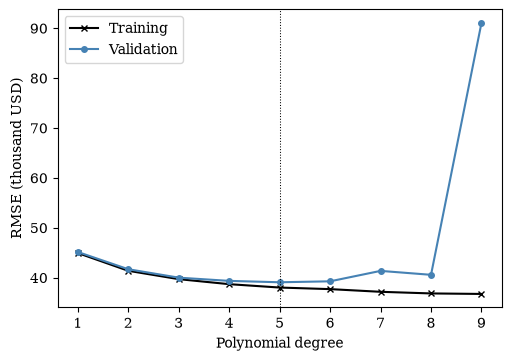

In [14]:
plot_validation_curve(degrees, rmse_train, rmse_validation, dmin)

The smallest mean validation RMSE occurs at degree 5, about 39.1 thousand USD.
The training error generally falls as the model becomes more flexible, but
higher degrees have larger validation errors, indicating overfitting.

#### A convenience display of the same scores

If all we are interested in is plotting the validation curve, we can use 
[`ValidationCurveDisplay`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ValidationCurveDisplay.html)
as an alternative. We construct it from the score arrays
already computed; there is no need to rerun CV. With the original negative
scores, `negate_score=True` plots positive RMSE.

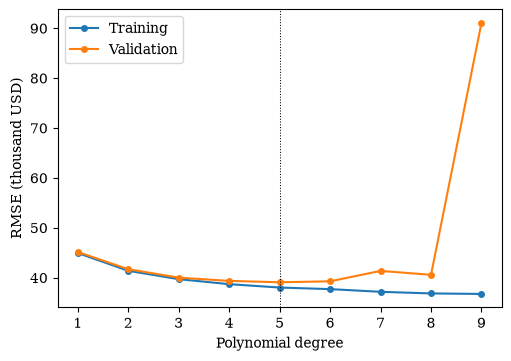

In [15]:
from sklearn.model_selection import ValidationCurveDisplay

# Create display object from the training and validation scores
display = ValidationCurveDisplay(
    param_name='poly__degree',
    param_range=degrees,
    train_scores=train_scores,
    test_scores=validation_scores,
    score_name='RMSE (thousand USD)',
)
# Plot the training and validation curves against the polynomial degree
fig, ax = plt.subplots(figsize=(5, 3.5), layout='constrained')
display.plot(
    ax=ax,
    negate_score=True,
    std_display_style=None,
    line_kw={'marker': 'o', 'markersize': 4},
)
ax.axvline(dmin, ls=':', lw=0.75, c='black')
ax.set(xlabel='Polynomial degree', xticks=degrees)
_ = ax.legend(['Training', 'Validation'])

The downside is that this approach is less flexible, for example if we want to control the plot style of the training and validation lines separately.

### Selecting and evaluating the final model

In the previous section, we only determined the optimal polynomial degree. The next
step in the CV workflow is to refit the selected model on the entire training set.
Both steps can be combined and automated using 
[`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html),
which can optionally refit the selected model on all training observations after CV selection.
`GridSearchCV` can cross-validate multiple hyperparameters simultaneously,
and we pass these as a dictionary of parameter names and candidate values. 

The following code illustrates this for the polynomial degree, using the same pipeline, folds, and scorer.
We pass `refit=True` to refit the selected model on all training observations after CV selection.

In [16]:
from sklearn.model_selection import GridSearchCV

# Define hyperparameter grid for polynomial degree
param_grid = {'poly__degree': degrees}

# Create a GridSearchCV object
poly_cv = GridSearchCV(
    pipe,  # estimator or pipeline
    param_grid=param_grid,  # dictionary of candidate parameter values
    cv=cv_splitter,  # cross-validation splitter
    scoring=scoring,  # scoring rule
    n_jobs=4,  # number of parallel jobs
    refit=True,  # refit the selected model on all training observations
)

# Run cross-validation and final fit on the training sample
poly_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'poly__degree': array([1, 2, ..., 6, 7, 8, 9])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, defaul

After the fit completes, the attribute `best_params_` gives the chosen parameter values.
`best_score_` is their mean CV score, a *selection score*.
`best_estimator_` contains the fitted pipeline refitted on the entire training sample,
ready to predict new observations. Before doing that, we can inspect the selected polynomial degree and its mean CV score.

In [17]:
print(poly_cv.best_params_)
print(f'CV selection RMSE: {-poly_cv.best_score_:.3f}')

{'poly__degree': np.int64(5)}
CV selection RMSE: 39.087


The above output confirms that the selected degree is 5, with a mean CV RMSE of about 39.1 thousand USD.

We now use the refitted pipeline to predict prices in `X_test`. We evaluate these
predictions with
[`root_mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html)
for RMSE in thousands of USD and
[`r2_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html)
for $R^2$. These test scores evaluate the selected model on observations excluded
from fitting and cross-validation.

In [18]:
from sklearn.metrics import r2_score, root_mean_squared_error

# Reference to the refitted best estimator
estimator = poly_cv.best_estimator_

# Evaluate the refitted model on the independent test sample
y_test_pred = estimator.predict(X_test)

# Compute RMSE and R² on the test sample
test_rmse = root_mean_squared_error(y_test, y_test_pred)
test_r2 = r2_score(y_test, y_test_pred)

print(f'Test RMSE (thousand USD): {test_rmse:.3f}')
print(f'Test R²: {test_r2:.3f}')

Test RMSE (thousand USD): 37.626
Test R²: 0.744


<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Repeat the polynomial-degree grid search using $R^2$ as the scoring criterion.
   Keep the same training observations, candidate degrees, and CV folds.
   Set `scoring='r2'`; larger scores indicate better predictions.
2. Report the selected degree and its mean validation $R^2$. Does the selected
   degree differ from the one chosen using RMSE?

</div>
<span style="display: none;">YourTurnEnd</span>

***
## Principal component regression

### A geometric introduction to principal component analysis

Principal component regression (PCR) is based on principal component analysis (PCA),
which finds perpendicular directions that successively capture the greatest remaining
variation in the data.
Geometrically, PCA rotates the original axes to align with the directions of greatest
variation in the predictors. PCA itself is an unsupervised machine learning method
that does not use the response variable. However, we'll later combine PCA with
regression to form PCR, a supervised learning method. We will use cross-validation
to select the number of principal components in PCR.

To make the rotation visible, we simulate 100 observations directly from a bivariate
normal distribution with zero means, standard deviations of 1.5 for $x_1$ and 1
for $x_2$, and a correlation of 0.8.
This bivariate normal sample is generated by the following function:

In [19]:
def generate_bivariate_normal(N=100, sigma1=1.5, rho=0.8):
    """
    Generate a synthetic bivariate normal dataset for PCA demonstration.

    Parameters
    ----------
    N : int
        Number of observations to generate
    sigma1 : float
        Standard deviation of the first variable
    rho : float
        Correlation coefficient between the two variables

    Returns
    -------
    X : array of shape (N, 2)
        Generated synthetic dataset with two centered variables
    """
    import numpy as np

    rng = np.random.default_rng(seed=1234)
    cov = np.array([[sigma1**2, sigma1 * rho], [sigma1 * rho, 1]])
    X = rng.multivariate_normal(mean=[0, 0], cov=cov, size=N)
    # Center the variables to have mean zero
    X = X - X.mean(axis=0)
    return X

We then fit a two-component PCA, which centers the sample without rescaling the variables.
In scikit-learn, this is implemented in the
[`PCA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
class. As usual in scikit-learn, the `fit()` method estimates the principal components from the training data, and the `transform()` method projects the original data onto these components. 
These two steps can be combined in a single call to `fit_transform()`.

In [20]:
from sklearn.decomposition import PCA

# Create a bivariate normal demo dataset
X = generate_bivariate_normal(N=100, rho=0.8)

# Set up PCA with 2 components
pca = PCA(n_components=2)

# Perform PCA on the synthetic dataset
X_pc = pca.fit_transform(X)

print('Explained variance fractions:', pca.explained_variance_ratio_)

Explained variance fractions: [0.91430695 0.08569305]


As reported above, for this synthetic sample, the first principal component captures about 91% of the variation in the predictors, while the second captures about 9%.
This is to be expected given the high correlation between $x_1$ and $x_2$. 

We use the following function `plot_pca_demo()` to visualize the original data, the principal components, and the rotated data. The first plot shows the original data with the principal components as arrows. The second plot shows the data projected onto the principal components, illustrating how PCA captures the directions of greatest variance.

In [21]:
def plot_pca_demo(X, X_pc, pca):
    """
    Plot the original and PCA-transformed datasets with principal axes.

    Parameters
    ----------
    X : array of shape (N, 2)
        Original dataset
    X_pc : array of shape (N, 2)
        PCA-transformed dataset
    pca : PCA object
        Fitted PCA object containing mean and components
    """
    import matplotlib.pyplot as plt
    import numpy as np

    _fig, axes = plt.subplots(
        1, 2, figsize=(6.5, 3.5), layout='constrained', sharex=True, sharey=True
    )

    # Data used for plotting the principal axes and arrows
    origins = [pca.mean_, np.zeros(2)]
    directions = [pca.components_, np.eye(2)]

    colors = ['black', 'red']
    lims = (-6, 6)

    for i, ax in enumerate(axes):
        # Plot the original or PCA-transformed data
        data = X if i == 0 else X_pc
        ax.scatter(data[:, 0], data[:, 1], s=18, c='none', ec='steelblue', lw=0.6)

        ax.set_xlabel('$x_1$' if i == 0 else 'PC1')
        ax.set_ylabel('$x_2$' if i == 0 else 'PC2')
        ax.set_title('Before PCA' if i == 0 else 'After PCA')
        ax.set(xlim=lims, ylim=lims, aspect=1)

        # Draw each principal axis and an arrow
        for j in range(2):
            # Scale the arrow length by 3 std. dev. to make it visible in the plot
            arrow = 3 * np.sqrt(pca.explained_variance_[j]) * directions[i][j]
            endpoint = origins[i] + arrow
            ax.axline(origins[i], endpoint, c=colors[j], lw=1, label=f'PC{j + 1}')
            ax.annotate(
                '',
                xy=endpoint,
                xytext=origins[i],
                arrowprops={'arrowstyle': '->', 'lw': 2, 'color': colors[j]},
            )

    axes[0].legend()

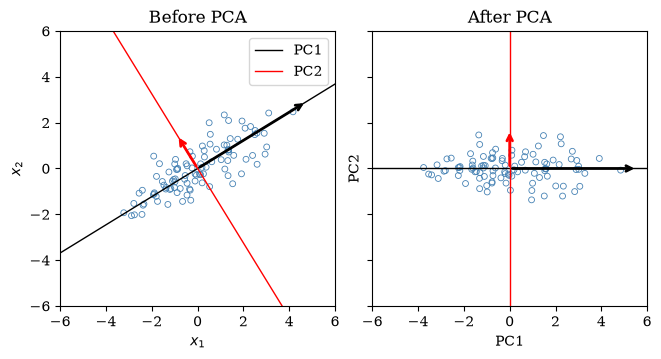

In [22]:
plot_pca_demo(X, X_pc, pca)

Before PCA, the cloud is diagonal. The black PC1 axis follows the direction with the greatest variation; the red PC2 axis is perpendicular to it. 
After PCA, the same cloud
lies along the horizontal PC1 axis. Both panels use identical axis scales, so
the change is a rotation. The arrows show the same principal directions
before and after rotation, with lengths equal to three times the component standard
deviations to improve visibility.

Keeping both components preserves all
information in the centered data. Keeping only PC1 would replace each point
with its horizontal coordinate in the right panel, discarding the smaller
vertical variation along PC2.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Use `generate_bivariate_normal()` with `rho=0`, keeping the other arguments
   unchanged. Repeat PCA and its visualization.
2. Compare the principal directions and explained variance fractions with the
   original example. Why do uncorrelated variables not necessarily contribute
   equal variance?

</div>
<span style="display: none;">YourTurnEnd</span>

### Principal component regression with polynomial features

We now return to the Ames data and use five predictors: `LivingArea`, `LotArea`,
`YearBuilt`, `OverallQuality`, and `Fireplaces`. We treat quality, which is measured on a scale of 1-10, as a single
continuous covariate here; Workshop 2 compares its numeric and categorical
representations. As before, we load the data with the selected predictors and
reserve 30% of the observations for testing, using the same random seed.

In [23]:
# Features used for PCR
features_pcr = ['LivingArea', 'LotArea', 'YearBuilt', 'OverallQuality', 'Fireplaces']

# Load the Ames housing data for PCR
X_pcr, y_pcr = load_ames_data(file, features_pcr, target)

# Create the same 70/30 train-test split for PCR
X_pcr_train, X_pcr_test, y_pcr_train, y_pcr_test = train_test_split(
    X_pcr, y_pcr, test_size=0.3, random_state=1234
)

To turn our polynomial regression pipeline into PCR, we insert PCA before the
regression step. The two scalers have different purposes: scaling the inputs
improves the numerical behavior of powers and interactions, while scaling the
expanded columns gives them comparable weight in PCA. We use `PCA(..., svd_solver='full')`
because the covariance-based solver is more sensitive to numerical errors when
the polynomial columns are highly correlated.

Our scaling choices affect which directions PCA identifies as having the most
variation. If we scale the polynomial features differently, PCA may retain
different components, and the resulting PCR model may make different predictions.
Scaling can help make the calculations more stable, but we still need
cross-validation to check how accurately the model predicts house prices.

For now, we set `n_components=0.9`. A fractional value tells PCA to retain enough
components to explain more than that fraction of predictor variance. However,
components that explain little predictor variance may still help predict prices.
We will therefore later use predictive CV scores to choose this threshold.

In [24]:
# Target fraction of variance to retain in PCA
pca_variance = 0.9

# Build a pipeline for degree-5 PCR with PCA
pipe_pcr = Pipeline(
    steps=[
        ('input_scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=5, include_bias=False)),
        ('scale', StandardScaler()),
        ('pca', PCA(n_components=pca_variance, svd_solver='full')),
        ('lr', LinearRegression(fit_intercept=True)),
    ]
)

### PCR versus simple polynomial regression

We first compare polynomial regression with PCR while holding the degree fixed
at 5. Both models use the same five predictors, observations, scaling, scorer, and
folds, so the only difference is the PCA step. This lets us see how reducing the
expanded predictor space affects an overly flexible polynomial model.

For convenience, we repeat the simple polynomial pipeline code from the previous section:

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Build a pipeline for the simple polynomial regression with degree 5
poly5 = Pipeline(
    steps=[
        ('input_scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=5, include_bias=False)),
        ('scale', StandardScaler()),
        ('lr', LinearRegression(fit_intercept=True)),
    ]
)

We can now run cross-validation on both pipelines and compare their mean validation RMSEs.

In [26]:
from sklearn.model_selection import cross_val_score

# Compute cross-validation scores for the simple polynomial
poly5_scores = cross_val_score(
    poly5,  # estimator or pipeline
    X_pcr_train,  # training predictors
    y_pcr_train,  # training target
    cv=cv_splitter,  # cross-validation splitter
    scoring=scoring,  # scoring rule
    n_jobs=4,  # number of parallel jobs
)

# Compute cross-validation scores for the PCR model
pcr5_scores = cross_val_score(
    pipe_pcr,  # estimator or pipeline
    X_pcr_train,  # training predictors
    y_pcr_train,  # training target
    cv=cv_splitter,  # cross-validation splitter
    scoring=scoring,  # scoring rule
    n_jobs=4,  # number of parallel jobs
)

# Compare the mean validation RMSEs for both models
df_degree5 = pd.DataFrame(
    {
        'Model': ['Degree 5 polynomial', 'Degree 5 PCR'],
        'Mean validation RMSE': [(-poly5_scores).mean(), (-pcr5_scores).mean()],
    }
)
df_degree5

,Model,Mean validation RMSE
0,Degree 5 polynomial,246.254881
1,Degree 5 PCR,39.528431


At degree 5, PCR reduces mean validation RMSE from about 246.3 to 39.5 thousand
USD. Since both models use the same features, we can attribute this difference
to the PCA step.

To see which components PCA retains, we fit the PCR pipeline on the entire
training sample and inspect its attributes. This is necessary because the CV
functions fitted their own copies of the pipeline. We can access each fitted
transformation through the `named_steps` dictionary.

In [27]:
# Refit the PCR pipeline on the entire training sample
pipe_pcr.fit(X_pcr_train, y_pcr_train)

# Report number of expanded features and retained components
pca_step = pipe_pcr.named_steps['pca']
print(f'Expanded features: {pca_step.n_features_in_}')
print(f'Retained components: {pca_step.n_components_}')

Expanded features: 251
Retained components: 21


The polynomial expansion creates 251 features, but PCA retains only 21 components.
Together, these components explain at least 90% of the variation in the expanded
predictors, as specified by `pca_variance`.

We can also look at how much variance each component explains. We extract these
fractions from the fitted estimator as follows:

In [28]:
# Obtain the explained variance fractions for the retained components
var_expl = pca_step.explained_variance_ratio_

We can then use these statistics to create the bar chart:

In [29]:
def plot_pcr_variance(var_expl, n_comp=10, target_var=0.9):
    """
    Plot the explained variance fractions for the retained components in PCR.

    Parameters
    ----------
    var_expl : array of shape (n_components,)
        Explained variance fractions for the retained components
    n_comp : int
        Number of components to plot
    target_var : float
        Target variance to indicate on the plot
    """
    import matplotlib.pyplot as plt
    import numpy as np

    _fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')

    # Component number shown on the x-axis
    n_comp = min(n_comp, len(var_expl))
    components = np.arange(1, n_comp + 1)

    bars = ax.bar(components, var_expl[:n_comp], color='steelblue')
    ax.set_ylabel('Fraction of predictor variance')
    ax.set_xlabel('Principal component')
    ax.set_xticks(components)
    ax.set_ylim(0, 1.05)

    # Cumulative explained variance on a second y-axis
    ax_cum = ax.twinx()
    cum_var_expl = np.cumsum(var_expl)
    cumul = ax_cum.plot(components, cum_var_expl[:n_comp], c='black', marker='o', ms=4)
    ax_cum.set_ylabel('Cumulative fraction of predictor variance')
    ax_cum.set_ylim(0, 1.05)
    if target_var is not None:
        ax_cum.axhline(target_var, c='black', ls='--', lw=1)
        ax.text(
            0.5,
            target_var - 0.025,
            f'Target variance: {target_var:.2f}',
            c='black',
            va='top',
            ha='left',
            fontsize=10,
        )

    ax.legend(
        [bars, cumul[0]],
        ['Variance explained', 'Cumulative variance'],
        loc='center right',
    )
    ax.set_title(f'PCR: first {n_comp} retained components')

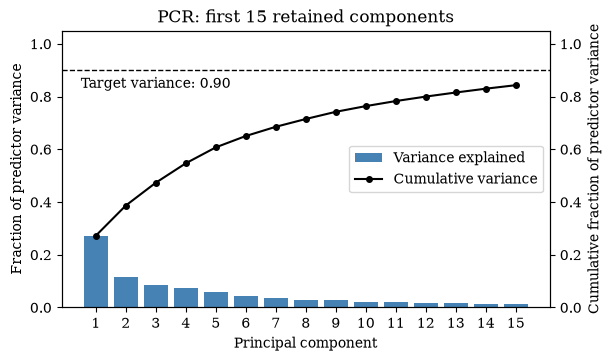

In [30]:
# Number of components to plot
n_comp = 15

plot_pcr_variance(var_expl, n_comp=n_comp, target_var=pca_variance)

As you can see from the plot, the first component explains about 27% of the
variance and the second about 11%. The black line shows the cumulative fraction
explained by the first $k$ components. The first 15 components together explain
about 84%, so the curve has not yet reached the dashed 90% threshold. We need
21 components to reach that threshold, which is why PCA retains 21 components in the fitted
pipeline.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Increase the PCA variance threshold from `0.9` to `0.95`, keeping polynomial
   degree 5. Refit using the existing training data and repeat cross-validation
   with the same folds and scoring rule.
2. Compare the retained component count and mean validation RMSE with the
   90% model. Does retaining more predictor variance improve prediction?

</div>
<span style="display: none;">YourTurnEnd</span>

### Cross-validating multiple hyperparameters

We can now use the grid search introduced earlier to choose two parameters jointly:
polynomial degree and the fraction of predictor variance retained by PCA. The
names `poly__degree` and `pca__n_components` follow the same `step__parameter`
convention as before.

With four degrees and five variance thresholds, we have 20 combinations to
compare. We use the same shuffled five-fold splitter and negative-RMSE scorer.
With `refit=True`, `GridSearchCV` then refits the selected pipeline on the entire
five-predictor training sample.

We redefine the CV splitter and scoring metric here for clarity, but they are the same as before since we are using the same seed.

In [31]:
from sklearn.model_selection import GridSearchCV, KFold

# Candidate degrees and variance thresholds (20 combinations)
param_grid = {
    'poly__degree': [2, 3, 4, 5],
    'pca__n_components': [0.9, 0.95, 0.975, 0.99, 0.999],
}

# Define the CV splitter
cv_splitter = KFold(n_splits=5, shuffle=True, random_state=1234)

# Define the scoring metric
scoring = 'neg_root_mean_squared_error'

# Create a GridSearchCV object for PCR
pcr_cv = GridSearchCV(
    pipe_pcr,  # estimator or pipeline
    param_grid,  # candidate parameter values
    cv=cv_splitter,  # cross-validation splitter
    scoring=scoring,  # scoring rule
    n_jobs=4,  # number of parallel jobs
    refit=True,  # refit on all training observations
)

pcr_cv.fit(X_pcr_train, y_pcr_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'pca__n_components': [0.9, 0.95, ...], 'poly__degree': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose 

As before, the attribute `best_params_` tells us which parameter values were selected.
Since our scorer returns negative RMSE, we negate `best_score_` to report the
CV selection RMSE. This is the mean validation RMSE for the selected PCR
candidate.

In [32]:
pcr_cv.best_params_

{'pca__n_components': 0.99, 'poly__degree': 3}

In [33]:
print(f'PCR CV selection RMSE: {-pcr_cv.best_score_:.3f}')

PCR CV selection RMSE: 27.897


We can also inspect the refitted PCA step to see how many expanded polynomial
features it received and how many components it retained. A fractional variance
threshold can lead to different numbers of components in different folds. The
counts below refer to the final refit on the entire training sample.

In [34]:
# Extract the PCA step from the best estimator
best_pca = pcr_cv.best_estimator_.named_steps['pca']

# Store number of features entering the model
features_in = best_pca.n_features_in_
# Store number of retained components
n_components = best_pca.n_components_

print(f'Number of expanded polynomial features: {features_in}')
print(f'Number of retained principal components: {n_components}')

Number of expanded polynomial features: 55
Number of retained principal components: 40


The search selects degree 3 with a variance threshold of 0.99 and a CV RMSE
of about 27.9 thousand USD. The polynomial expansion creates 55 features, and
the refitted PCR model retains 40 components. PCA therefore removes 15
components while retaining at least 99% of the variation in the expanded
predictors.

### Evaluating the selected models on the test sample

Our earlier polynomial degree search used only two predictors. Since we now
have five predictors, we need to select the polynomial degree again for this
feature set. We use the same degrees from 2 to 5, CV folds, and scoring metric
as in the PCR search. This lets each method choose its own model complexity:
polynomial regression selects the degree, while PCR also selects how much
predictor variance to retain.

With `refit=True`, each search refits its selected model on the entire training
sample.

In [35]:
# Select among degrees 2 to 5 using the same CV setup as PCR
poly_param_grid = {'poly__degree': [2, 3, 4, 5]}

poly_cv = GridSearchCV(
    poly5,  # estimator or pipeline
    poly_param_grid,  # candidate parameter values
    cv=cv_splitter,  # cross-validation splitter
    scoring=scoring,  # scoring rule
    n_jobs=4,  # number of parallel jobs
    refit=True,  # refit on all training observations
)
poly_cv.fit(X_pcr_train, y_pcr_train)

print(poly_cv.best_params_)
print(f'Polynomial CV selection RMSE: {-poly_cv.best_score_:.3f}')

{'poly__degree': 3}
Polynomial CV selection RMSE: 27.776


We can now compute the predictions for both models on the same independent test
sample. We then compute `root_mean_squared_error()` for RMSE in thousands of USD
and `r2_score()` for $R^2$ to compare the prediction accuracy.

In [36]:
from sklearn.metrics import r2_score, root_mean_squared_error

# Predict on test sample and compute RMSE and R² for simple polynomial model
y_poly_pred = poly_cv.predict(X_pcr_test)
poly_test_rmse = root_mean_squared_error(y_pcr_test, y_poly_pred)
poly_test_r2 = r2_score(y_pcr_test, y_poly_pred)

# Predict on test sample and compute RMSE and R² for PCR model
y_pcr_pred = pcr_cv.predict(X_pcr_test)
pcr_test_rmse = root_mean_squared_error(y_pcr_test, y_pcr_pred)
pcr_test_r2 = r2_score(y_pcr_test, y_pcr_pred)

# Compare the selected degrees, model dimensions, and test scores
poly_features = poly_cv.best_estimator_.named_steps['poly'].n_output_features_
df_comparison = pd.DataFrame(
    {
        'Model': ['Selected polynomial', 'Selected PCR'],
        'Degree': [
            poly_cv.best_params_['poly__degree'],
            pcr_cv.best_params_['poly__degree'],
        ],
        'Regressors': [poly_features, n_components],
        'Test RMSE': [poly_test_rmse, pcr_test_rmse],
        'Test R²': [poly_test_r2, pcr_test_r2],
    }
)
print(df_comparison.to_string(index=False))

              Model  Degree  Regressors  Test RMSE  Test R²
Selected polynomial       3          55  28.588499 0.852468
       Selected PCR       3          40  28.097610 0.857491


The polynomial and PCR cross-validations both select degree 3. Their CV selection
RMSEs are 27.776 and 27.897 thousand USD, respectively. On the test sample,
polynomial regression has RMSE of about 28.6 thousand USD, compared with
28.1 for PCR. The selected polynomial model uses 55 features; PCA reduces
PCR's 55 expanded features to 40 components.

This result depends on the sample and model-selection setup, including the
train-test split, CV folds, random seed, and candidate values. You should not
conclude that PCR always performs better on the test set. In fact, the results
here suggest that both methods perform very similarly, but PCR achieves this
result with fewer regressors.

<div style="padding: 0.8em 1em 0.5em 1em; border: 2pt solid #1d91c0;">
<p style="font-weight: bold; font-size: 1.5em; color: #1d91c0;">Your turn</p>

1. Add `OverallCondition` to the five PCR predictors. Keep the same training
   observations in the same order and reuse `cv_splitter`.
2. Rerun the same 20-combination grid search. Compare the CV RMSE, selected
   degree, variance threshold, and number of retained components with the
   five-predictor results. Use only the training sample for this comparison.
3. Does adding `OverallCondition` improve validation accuracy, and does the
   selected regression use fewer or more regressors? Explain how this relates
   to the selected polynomial degree.

</div>
<span style="display: none;">YourTurnEnd</span>

***
## List of functions used in this lecture

Each function name links to its official API documentation.
The [[go to section]](#Modeling-workflow) links point to the
relevant discussion in this notebook.

### NumPy functions

- [`argmin()`](https://numpy.org/doc/stable/reference/generated/numpy.argmin.html)
  Return the indices of minimum values along an axis.
  [[go to section]](#Choosing-the-polynomial-degree)

### scikit-learn classes and functions

#### Regression models (`sklearn.linear_model`)

- [`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)
  Fit ordinary least squares linear regression.
  [[go to section]](#Evaluating-a-quadratic-model)

#### Model selection and cross-validation (`sklearn.model_selection`)

- [`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
  Split observations into training and test samples.
  [[go to section]](#Data-preparation)
- [`KFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html)
  Divide observations into folds for cross-validation.
  [[go to section]](#Cross-validation-setup)
- [`cross_val_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
  Evaluate a single metric for an estimator using cross-validation.
  [[go to section]](#Evaluating-a-quadratic-model)
- [`cross_validate()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html)
  Evaluate one or more metrics using cross-validation and return timing data.
  [[go to section]](#Comparing-training-and-validation-errors)
- [`validation_curve()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.validation_curve.html)
  Compute training and validation scores over a range of parameter values.
  [[go to section]](#Choosing-the-polynomial-degree)
- [`ValidationCurveDisplay`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.ValidationCurveDisplay.html)
  Plot training and validation scores as a function of a parameter value.
  [[go to section]](#A-convenience-display-of-the-same-scores)
- [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
  Search specified hyperparameter combinations exhaustively using cross-validation.
  [[go to section]](#Selecting-and-evaluating-the-final-model)

#### Evaluation metrics (`sklearn.metrics`)

- [`root_mean_squared_error()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.root_mean_squared_error.html)
  Compute prediction RMSE.
  [[go to section]](#Selecting-and-evaluating-the-final-model)
- [`r2_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html)
  Compute the coefficient of determination.
  [[go to section]](#Selecting-and-evaluating-the-final-model)

#### Feature preprocessing (`sklearn.preprocessing`)

- [`PolynomialFeatures`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
  Generate polynomial and interaction features.
  [[go to section]](#Evaluating-a-quadratic-model)
- [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
  Standardize features by removing their mean and scaling to unit variance.
  [[go to section]](#Evaluating-a-quadratic-model)

#### Dimensionality reduction (`sklearn.decomposition`)

- [`PCA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
  Perform linear dimensionality reduction using principal component analysis.
  [[go to section]](#A-geometric-introduction-to-principal-component-analysis)

#### Pipelines (`sklearn.pipeline`)

- [`Pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
  Chain transformers and a final estimator.
  [[go to section]](#Evaluating-a-quadratic-model)